<a href="https://colab.research.google.com/github/Uwais-ur-Rehman/ML-Project/blob/main/Voting_classifier_Esemble.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

In [29]:
from sklearn.datasets import make_moons
x,y=make_moons(n_samples=5000,noise=0.2)

In [30]:
data={"x1":x[:,0],"x2":x[:,1],"y":y}

In [31]:
df=pd.DataFrame(data)

In [32]:
df

,x1,x2,y
0,-0.380550,1.000096,0
1,0.370384,-0.059353,1
2,1.043284,-0.507397,1
3,0.286985,0.909535,0
4,0.880266,0.395367,0
...,...,...,...
4995,-0.020452,0.879504,0
4996,0.441108,-0.501956,1
4997,-1.238566,0.289904,0
4998,0.222894,0.221430,1


In [33]:
import seaborn as sns

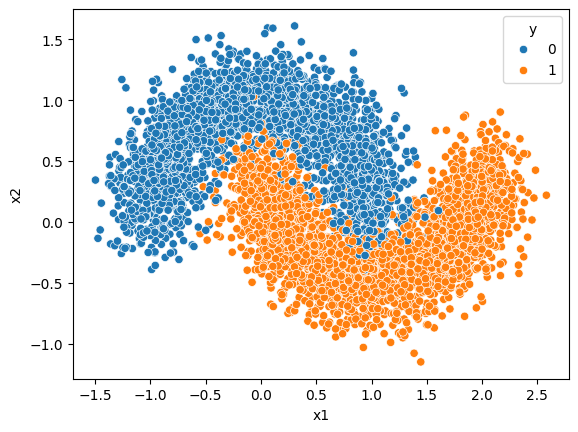

In [34]:
sns.scatterplot(x="x1",y="x2",hue='y',data=df)
plt.show()

In [37]:
X=df.iloc[:,:-1]
Y=df['y']

In [39]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=0)

In [40]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

In [41]:
dt= DecisionTreeClassifier()
svm=SVC()
nb=GaussianNB()

In [46]:
dt.fit(X_train,Y_train)
print(dt.score(X_train,Y_train)*100)
print(dt.score(X_test,Y_test)*100)

100.0
96.5


In [47]:
svc=svm.fit(X_train,Y_train)
print(svc.score(X_train,Y_train)*100)
print(svc.score(X_test,Y_test)*100)

96.42500000000001
98.4


In [48]:
gnb=nb.fit(X_train,Y_train)
print(gnb.score(X_train,Y_train)*100)
print(gnb.score(X_test,Y_test)*100)

86.825
88.2


In [49]:
li=[("dt1",DecisionTreeClassifier()),("sv1",SVC()),("gnb",GaussianNB())]

In [58]:
from sklearn.ensemble import VotingClassifier
vc= VotingClassifier(li,weights=[5,4,7])
vc.fit(X_train,Y_train)

VotingClassifier(estimators=[('dt1', DecisionTreeClassifier()), ('sv1', SVC()),
                             ('gnb', GaussianNB())],
                 weights=[5, 4, 7])

In [59]:
vc.score(X_train,Y_train)*100

97.625

In [60]:
vc.score(X_test,Y_test)*100

98.0

In [61]:
prd={"dt":dt.predict(X_test),"svm":svc.predict(X_test),"gnb":gnb.predict(X_test),"vc":vc.predict(X_test)}

In [62]:
pd.DataFrame(prd)

,dt,svm,gnb,vc
0,0,0,0,0
1,0,0,0,0
2,1,1,1,1
3,0,0,0,0
4,0,0,0,0
...,...,...,...,...
995,1,1,1,1
996,1,1,1,1
997,1,1,1,1
998,0,0,1,0
